<center><h1>Dong_Fengkai_HW4</h1></center>
<br>
<br>

Name: Fengkai Dong
<br>
Github Username: dfk0411
<br>
USC ID: 

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import pandas as pd
import numpy as np
import bootstrapped.bootstrap as bs
import bootstrapped.stats_functions as bs_stats
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.feature_selection import RFE
from sklearn.model_selection import StratifiedKFold
import statsmodels.api as sm
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB

Get the AReM Data Set

In [2]:
cols = ["time", "avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
acts = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
data = {}

for act in acts:
    data[act] = {}
    path = f"../data/AReM/{act}"
    for file in os.listdir(path):
        num = int(file.replace("dataset", "").replace(".csv", ""))
        if file.endswith(".csv"):
            df = pd.read_csv(
                f"{path}/{file}",
                comment="#",
                header=None,
                names=cols,
                sep=r"[,\s]+",
                engine="python",
                usecols=range(7)
            )
        data[act][num] = df

print(sum(len(data[act]) for act in acts))

88


### (b) Splitting Data

In [3]:
train_data = {}
test_data = {}

for act in acts:
    train_data[act] = {}
    test_data[act] = {}
    for num, df in data[act].items():
        if act in ["bending1", "bending2"]:
            if num in [1, 2]:
                test_data[act][num] = df
            else:
                train_data[act][num] = df
        else:
            if num in [1, 2, 3]:
                test_data[act][num] = df
            else:
                train_data[act][num] = df

print("Training data:", sum(len(train_data[a]) for a in acts))
print("Test data:", sum(len(test_data[a]) for a in acts))

Training data: 69
Test data: 19


### (c) Feature Extraction

In [4]:
series_cols = cols[1:]
feature_rows = []
instance = 1

for act in acts:
    for num in range(1, len(data[act])+1):
        df = data[act][num]
        row = {"Instance": instance}
        for i in range(len(series_cols)):
            col = series_cols[i]
            row[f"min{i+1}"] = df[col].min()
            row[f"max{i+1}"] = df[col].max()
            row[f"mean{i+1}"] = df[col].mean()
            row[f"median{i+1}"] = df[col].median()
            row[f"std{i+1}"] = df[col].std()
            row[f"1st quart{i+1}"] = df[col].quantile(0.25)
            row[f"3rd quart{i+1}"] = df[col].quantile(0.75)
        feature_rows.append(row)
        instance += 1

pd.DataFrame(feature_rows)

,Instance,min1,max1,mean1,median1,std1,1st quart1,3rd quart1,min2,max2,...,std5,1st quart5,3rd quart5,min6,max6,mean6,median6,std6,1st quart6,3rd quart6
0,1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
1,2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
2,3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
3,4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
4,5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
84,85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
85,86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
86,87,23.50,46.25,34.873229,35.25,4.531720,31.75,38.2500,0.0,14.82,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

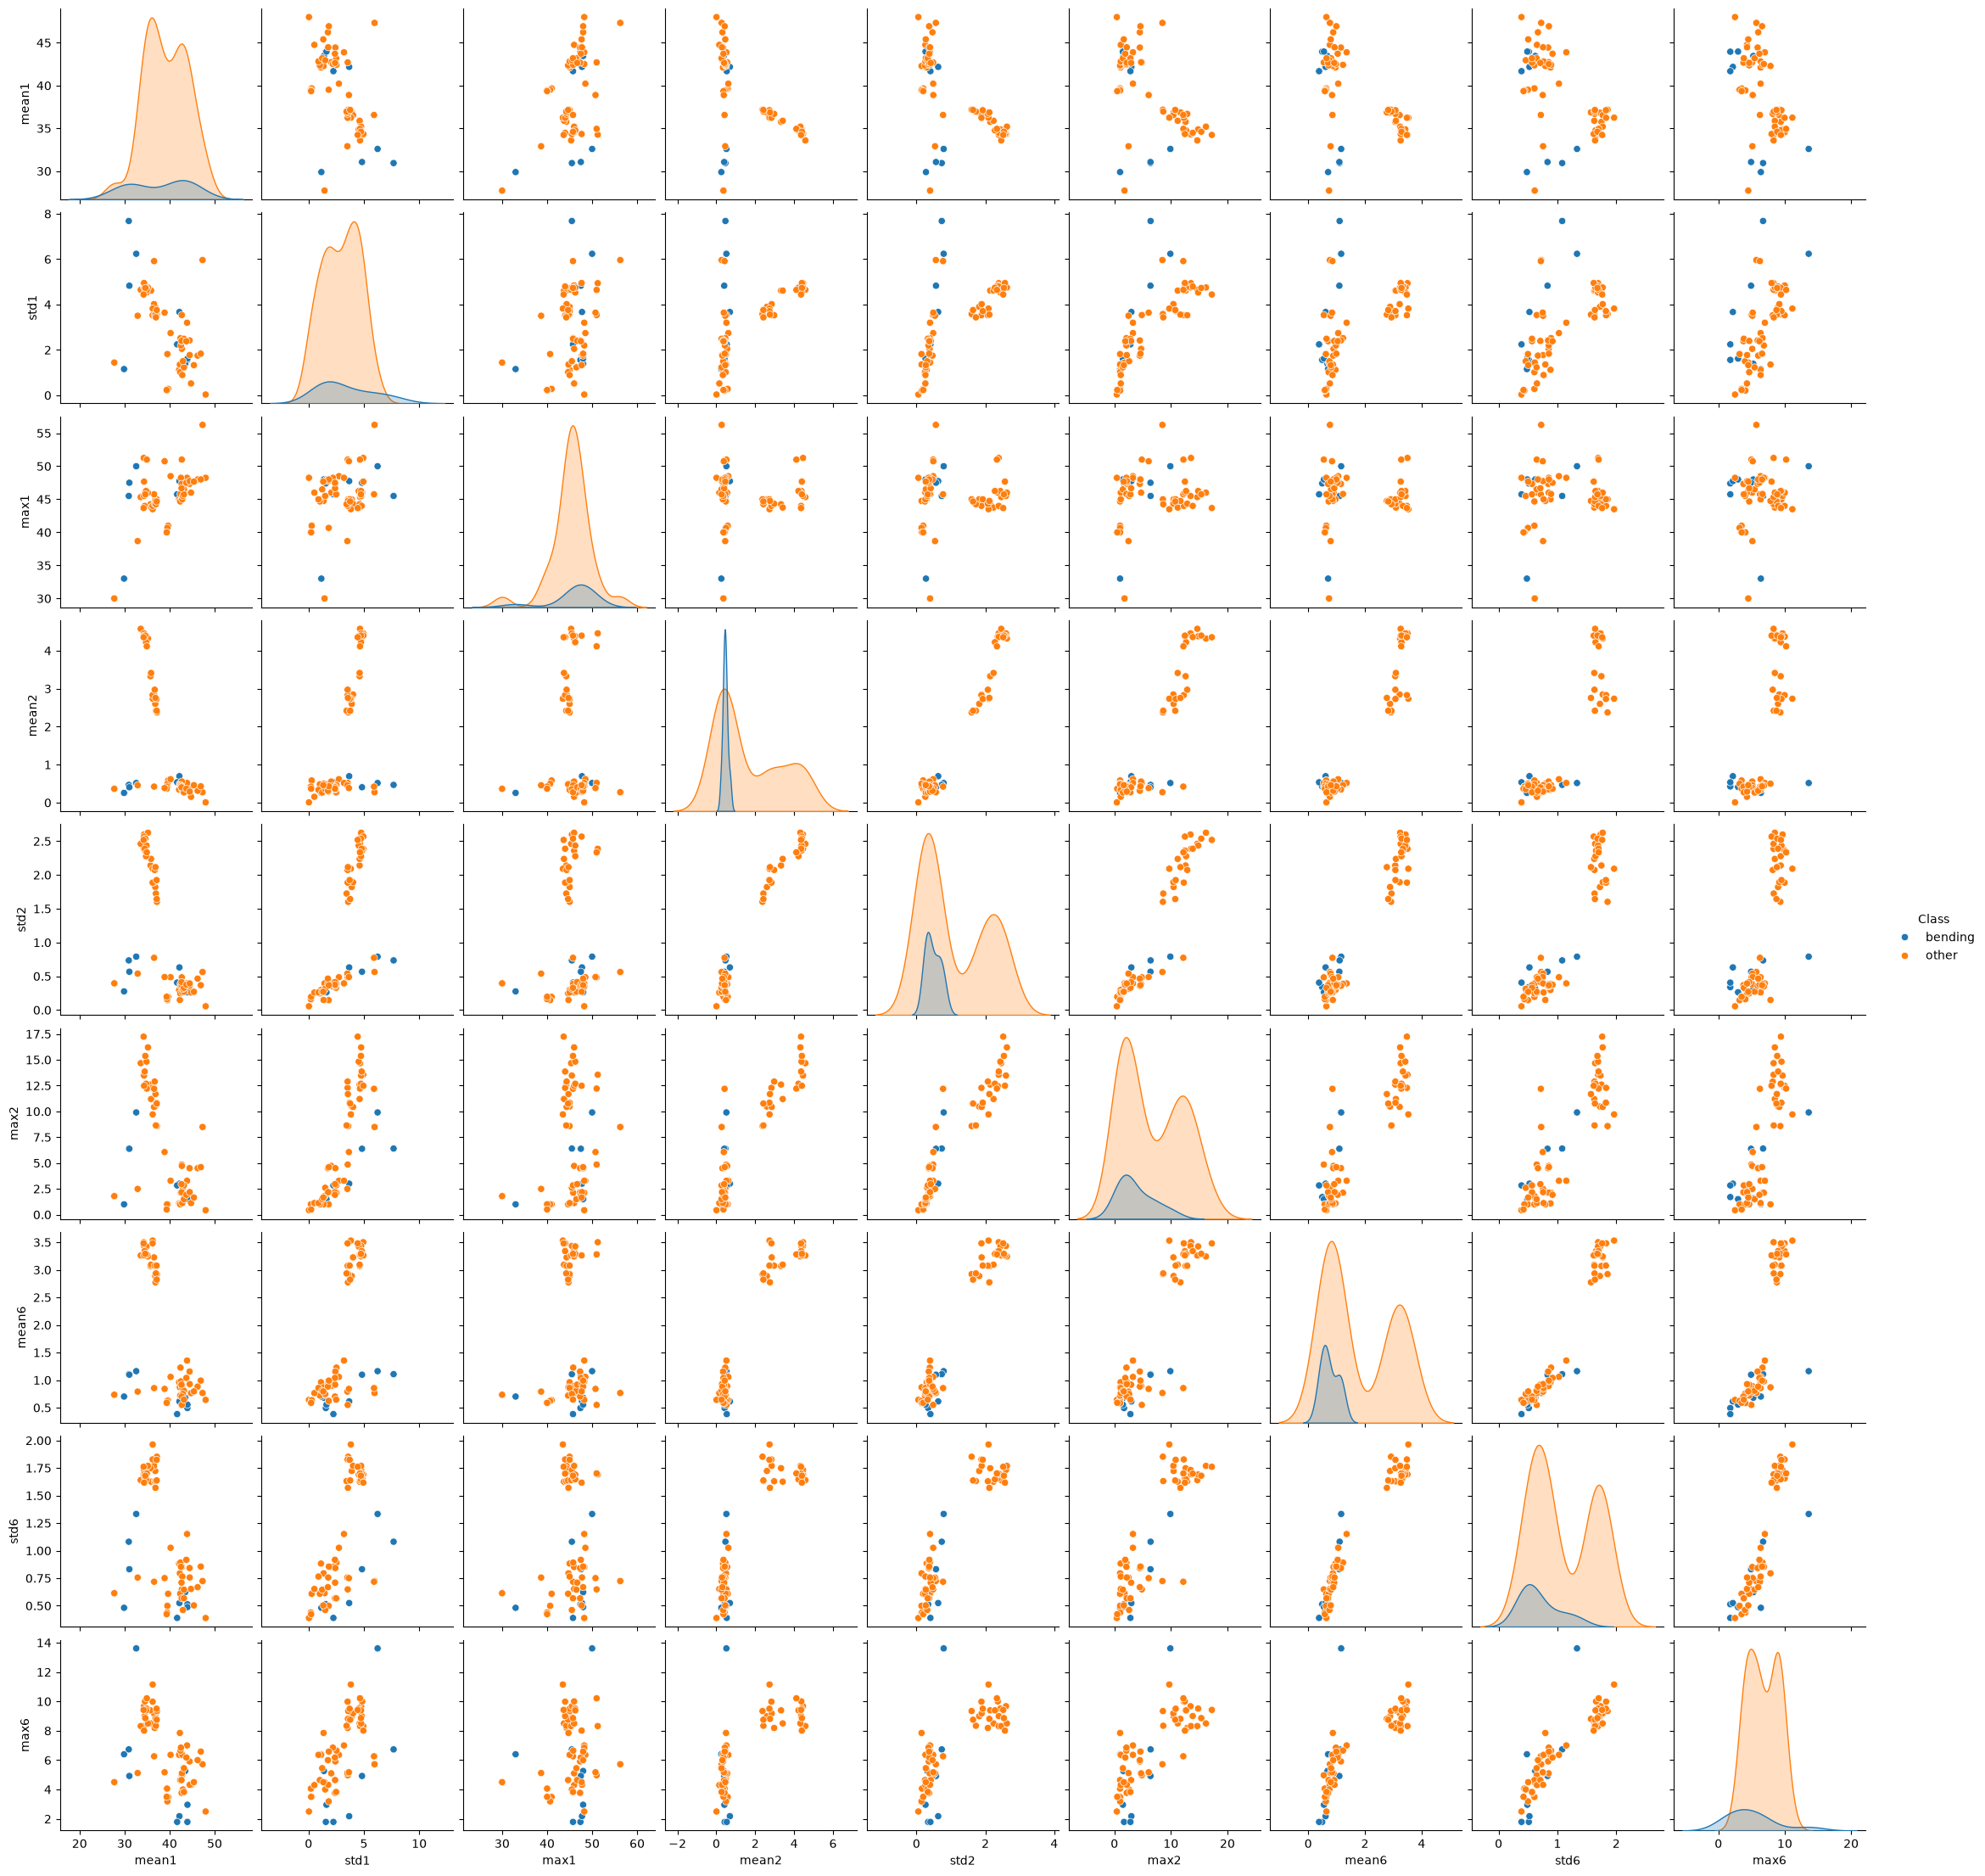

In [5]:
plot_rows = []

for act in acts:
    for num, df in train_data[act].items():
        row = {}
        if act in ["bending1", "bending2"]:
            row["Class"] = "bending"
        else:
            row["Class"] = "other"
        
        for i in [1, 2, 6]:
            col = series_cols[i - 1]
            row[f"mean{i}"] = df[col].mean()
            row[f"std{i}"] = df[col].std()
            row[f"max{i}"] = df[col].max()
        plot_rows.append(row)

plot_data = pd.DataFrame(plot_rows)
sns.pairplot(plot_data, hue="Class")
plt.show()

#### ii. Splitted Plots

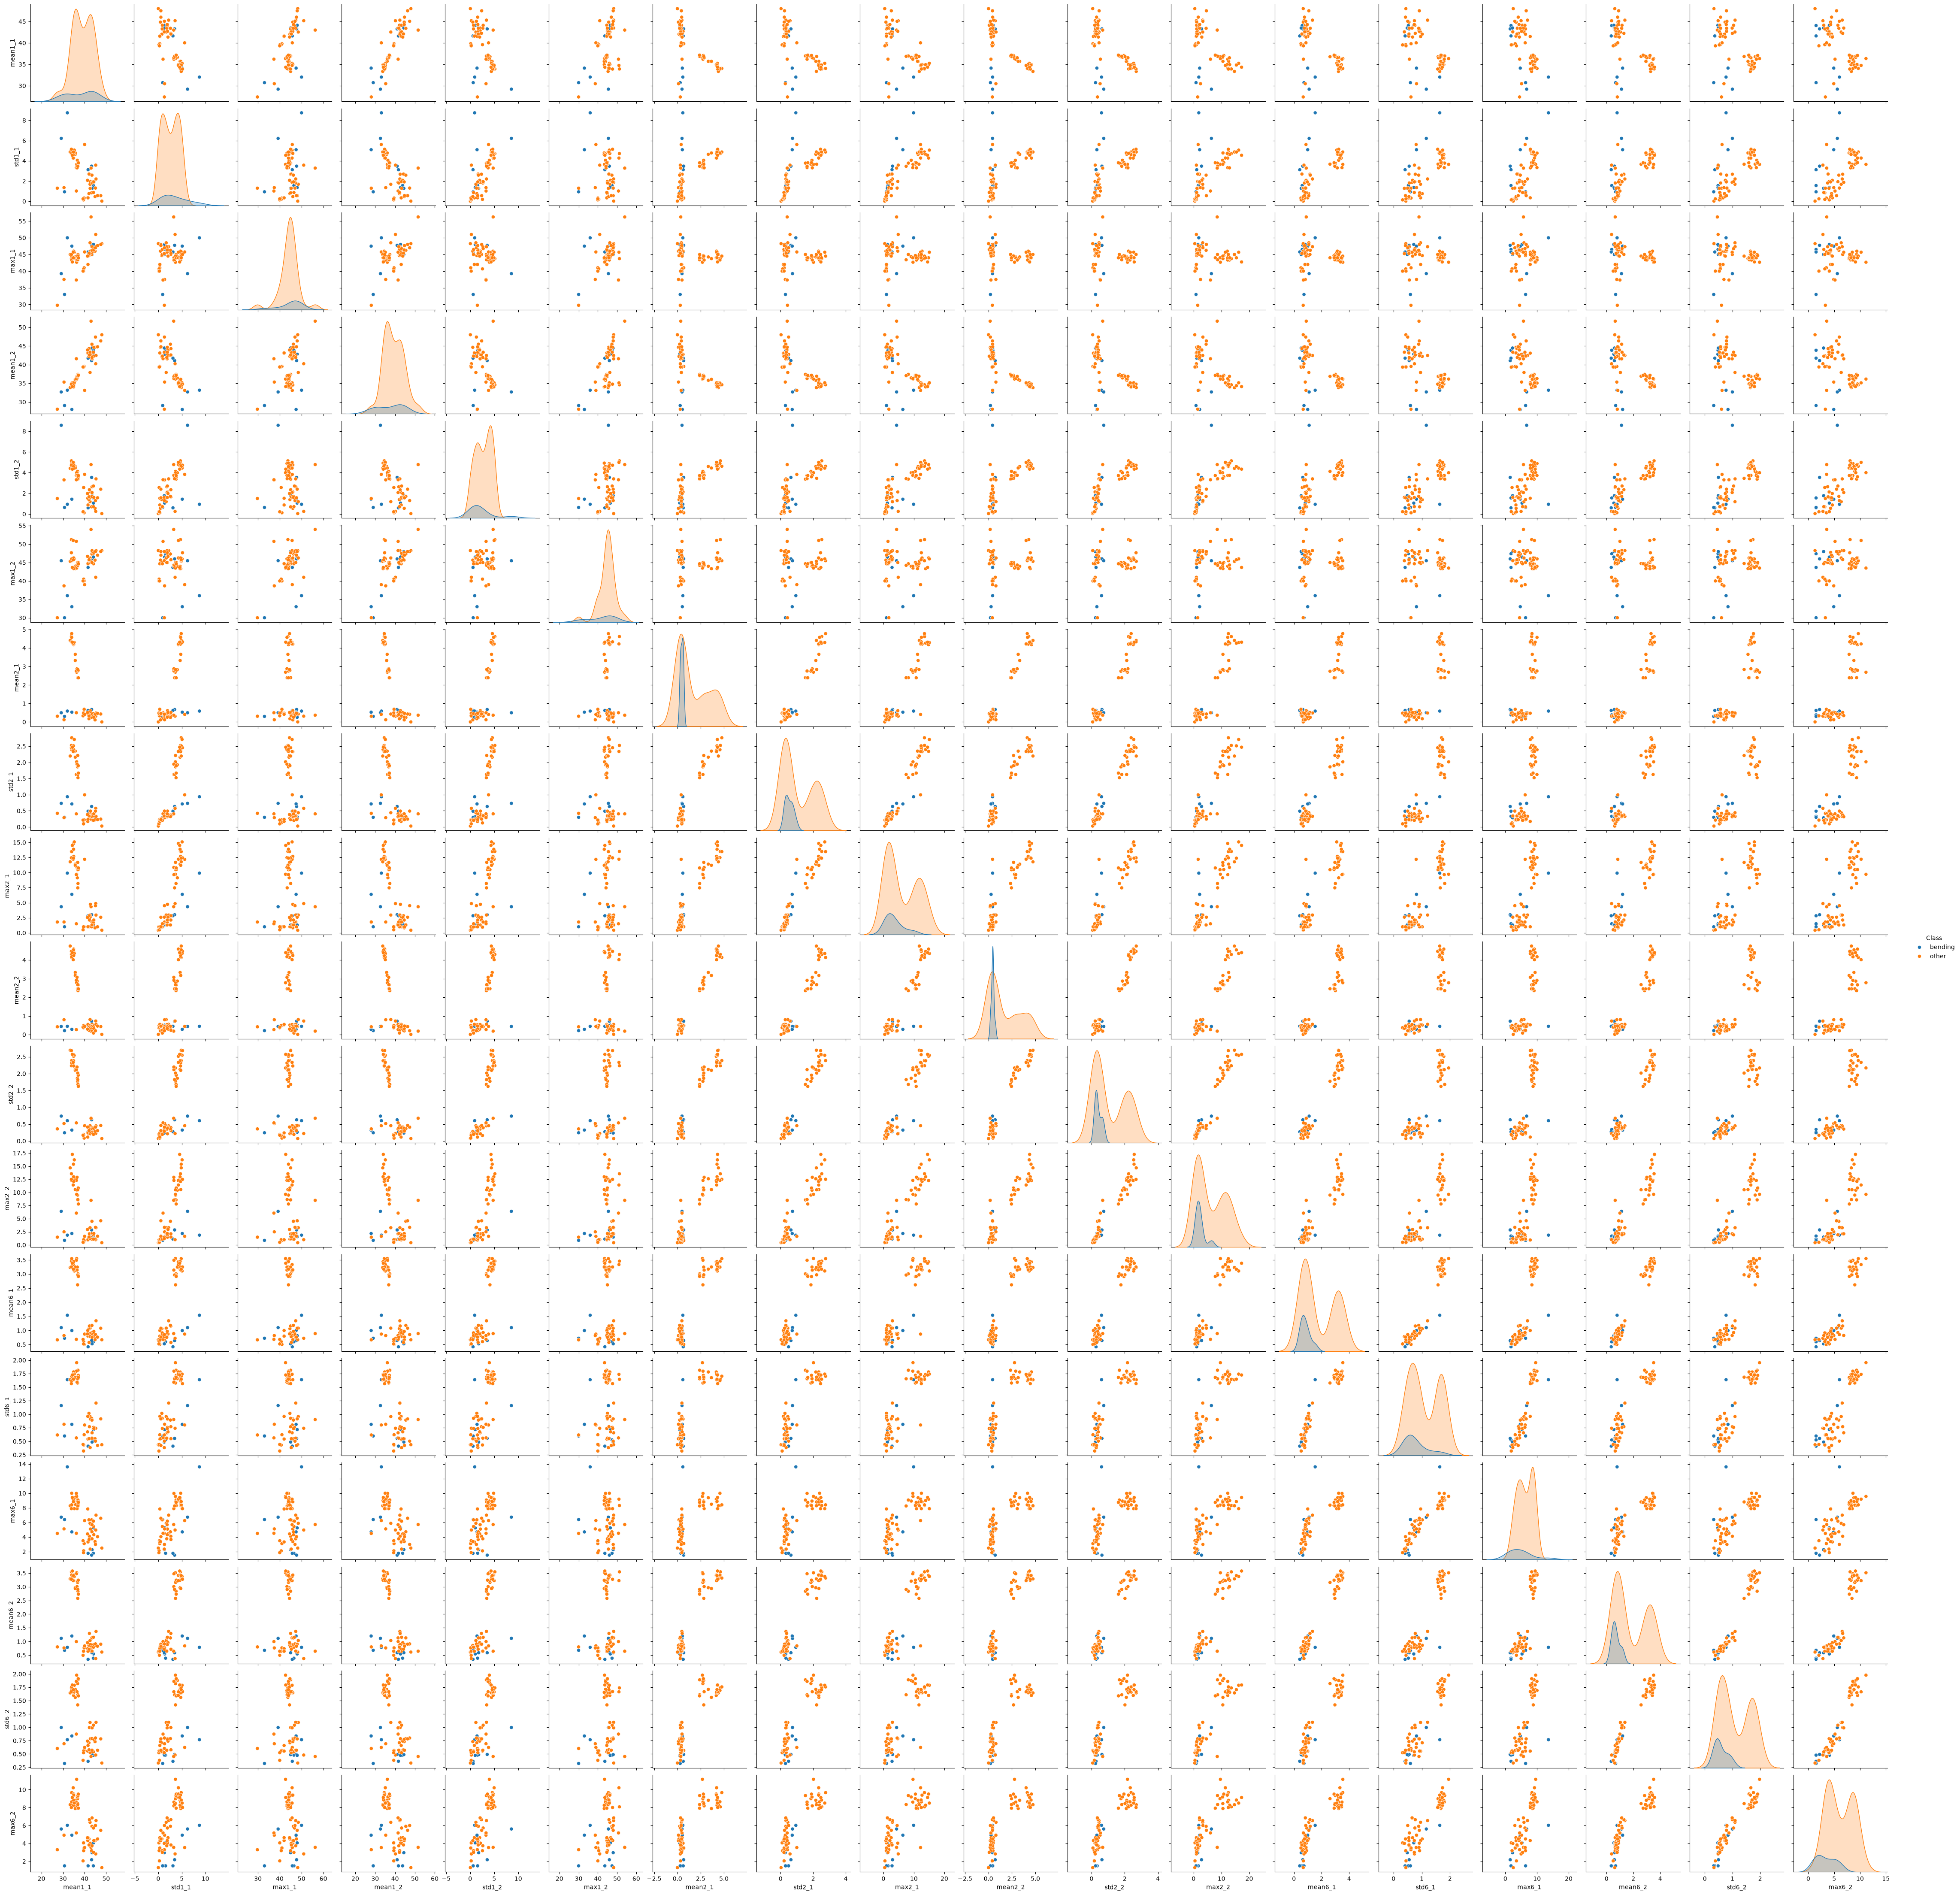

In [6]:
split_rows = []

for act in acts:
    for num, df in train_data[act].items():
        row = {}
        if act in ["bending1", "bending2"]:
            row["Class"] = "bending"
        else:
            row["Class"] = "other"

        for i in [1, 2, 6]:
            col = series_cols[i - 1]
            parts = np.array_split(df[col].values, 2)
            for j in range(2):
                part = parts[j]
                row[f"mean{i}_{j+1}"] = np.mean(part)
                row[f"std{i}_{j+1}"] = np.std(part, ddof=1)
                row[f"max{i}_{j+1}"] = np.max(part)
        split_rows.append(row)

split_data = pd.DataFrame(split_rows)
sns.pairplot(split_data, hue="Class")
plt.show()

There is no considerable difference compared with part (i). The bending observations are generally concentrated in a narrower region, but they still overlap with some of the other activities. Splitting the time series doesn't significantly improve the separation between the two classes.

#### iii. Time Series Segments

In [7]:
def make_features(dataset, l, binary=True):
    rows = []
    labels = []
    for act in acts:
        for df in dataset[act].values():
            row = {}
            for i in range(len(series_cols)):
                col = series_cols[i]
                parts = np.array_split(df[col].to_numpy(), l)
                for j in range(l):
                    part = pd.Series(parts[j])
                    name = f"{i+1}_{j+1}"
                    row[f"min{name}"] = part.min()
                    row[f"max{name}"] = part.max()
                    row[f"mean{name}"] = part.mean()
                    row[f"median{name}"] = part.median()
                    row[f"std{name}"] = part.std()
                    row[f"1st_quart{name}"] = part.quantile(0.25)
                    row[f"3rd_quart{name}"] = part.quantile(0.75)
            rows.append(row)
            if binary:
                if act in ["bending1", "bending2"]:
                    labels.append(1)
                else:
                    labels.append(0)
            else:
                labels.append(act)
    return pd.DataFrame(rows), np.array(labels)


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
res = []
for l in range(1, 21):
    x, y = make_features(train_data, l)
    n_features = x.shape[1]
    scores = np.zeros(n_features)

    for train_idx, val_idx in cv.split(x, y):
        x_train = x.iloc[train_idx]
        x_val = x.iloc[val_idx]
        y_train = y[train_idx]
        y_val = y[val_idx]

        base_model = LogisticRegression(C=1e8)
        rfe = RFE(base_model, n_features_to_select=1)
        rfe.fit(x_train, y_train)
        ranking = rfe.ranking_

        for p in range(1, n_features+1):
            selected = ranking <= p
            model = LogisticRegression(C=1e8)
            model.fit(x_train.loc[:, selected], y_train)
            scores[p - 1] += model.score(x_val.loc[:, selected], y_val)
    scores /= 5

    for p in range(1, n_features + 1):
        res.append({
            "l": l,
            "p": p,
            "CV Accuracy": scores[p - 1]
        })

cv_res = pd.DataFrame(res)
best_score = cv_res["CV Accuracy"].max()
best_res = cv_res[np.isclose(cv_res["CV Accuracy"], best_score)].sort_values(["l", "p"])
print("Best CV accuracy:", best_score)
best_res

Best CV accuracy: 1.0


,l,p,CV Accuracy
4,1,5,1.0
5,1,6,1.0
6,1,7,1.0
7,1,8,1.0
8,1,9,1.0
9,1,10,1.0
10,1,11,1.0
11,1,12,1.0
2780,12,9,1.0
3835,14,14,1.0


The correct way is to carry out feature selection separately within each training fold, and then evaluate the selected features on the corresponding validation fold.

The wrong way is to perform feature selection using the entire training dataset before cross-validation, because this allows information from the validation folds to influence feature selection.

#### iv. Confusion Matrix

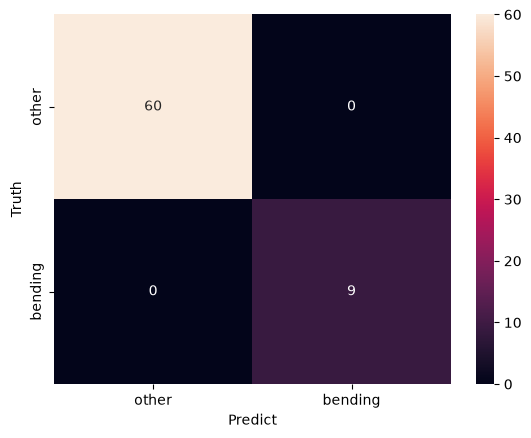

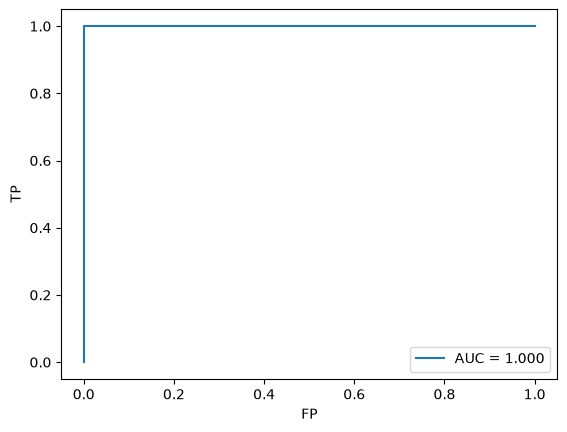

         Current function value: 0.000000
         Iterations: 35


d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\statsmodels\base\optimizer.py:536: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  callback(newparams)
d:\USC\Fall 

,Coefficient,p-value
const,5.986159,1.000000
3rd_quart1_1,-6.769935,0.999997
max2_1,-3.354674,0.999998
min5_1,5.832004,0.999989
max5_1,7.220751,0.999993
1st_quart5_1,1.810860,0.999998


In [8]:
best_l = 1
best_p = 5
x_train, y_train = make_features(train_data, best_l)
base_model = LogisticRegression(C=1e8)
rfe = RFE(base_model, n_features_to_select=best_p)
rfe.fit(x_train, y_train)
sel_features = x_train.columns[rfe.support_]
y_pred = rfe.predict(x_train)
y_prob = rfe.predict_proba(x_train)[:, 1]
cm = confusion_matrix(y_train, y_pred)

sns.heatmap(cm, annot=True, fmt="d", xticklabels=["other", "bending"], yticklabels=["other", "bending"])
plt.xlabel("Predict")
plt.ylabel("Truth")
plt.show()

fpr, tpr, thresholds = roc_curve(y_train, y_prob)
auc = roc_auc_score(y_train, y_prob)
plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.xlabel("FP")
plt.ylabel("TP")
plt.legend()
plt.show()

x_sel = x_train[sel_features]
x_sm = sm.add_constant(x_sel)
logit_res = sm.Logit(y_train, x_sm).fit()
pd.DataFrame({
    "Coefficient": logit_res.params,
    "p-value": logit_res.pvalues
})

#### v. Test Classifier

In [9]:
x_test, y_test = make_features(test_data, best_l)
test_acc = rfe.score(x_test, y_test)
print("Test accuracy:", test_acc)
print("Cross-validation accuracy:", best_score)

Test accuracy: 1.0
Cross-validation accuracy: 1.0


The test accuracy is 1.0, which is the same as the cross-validation accuracy.

#### vi. Separation

Yes. The two classes seem to be well-separated. The logistic regression model perfectly classifies the training data, and statsmodels reports a perfect-separation warning, so the logistic regression parameter estimates are unstable.

#### vii. Imbalance

Transformed intercept: -1.9213221843848705


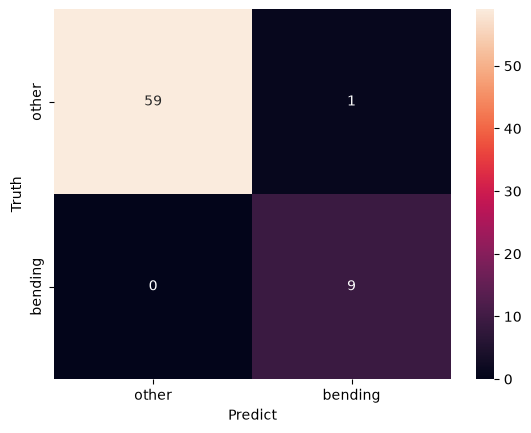

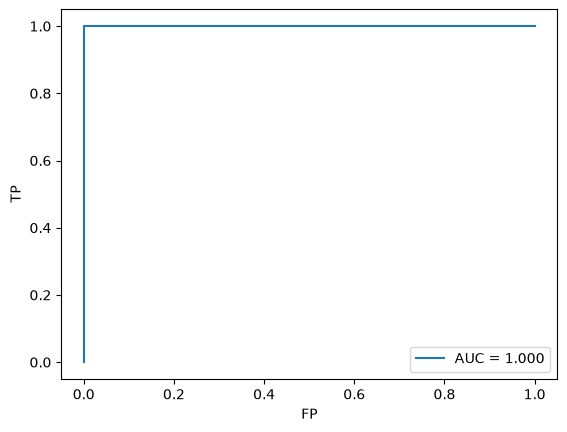

In [10]:
bending_idx = np.where(y_train == 1)[0]
other_idx = np.where(y_train == 0)[0]
np.random.seed(1)
sample_idx = np.concatenate([
    bending_idx,
    np.random.choice(other_idx, len(bending_idx), False)
])
x_case = x_sel.iloc[sample_idx]
y_case = y_train[sample_idx]
model = LogisticRegression(C=1e8)
model.fit(x_case, y_case)
pi = y_train.mean()
pi_sample = y_case.mean()

trans_intercept = model.intercept_[0] + np.log(pi / (1 - pi)) - np.log(pi_sample / (1 - pi_sample))
logit = x_sel.to_numpy() @ model.coef_[0] + trans_intercept
y_prob_case = 1 / (1 + np.exp(-logit))
y_pred_case = (y_prob_case >= 0.5).astype(int)
print("Transformed intercept:", trans_intercept)

sns.heatmap(
    confusion_matrix(y_train, y_pred_case),
    annot=True,
    fmt="d",
    xticklabels=["other", "bending"],
    yticklabels=["other", "bending"]
)
plt.xlabel("Predict")
plt.ylabel("Truth")
plt.show()

fpr, tpr, _ = roc_curve(y_train, y_prob_case)
auc_case = roc_auc_score(y_train, y_prob_case)
plt.plot(fpr, tpr, label=f"AUC = {auc_case:.3f}")
plt.xlabel("FP")
plt.ylabel("TP")
plt.legend()
plt.show()

The classes are imbalanced, with 60 observations in the other class and 9 observations in the bending class. After the adjustment, the model misclassifies one observation from the other class as bending, while all bending observations are classified correctly. The AUC remains 1.0.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [11]:
C_values = np.logspace(-4, 4, 10)
l1_res = []

for l in range(1, 21):
    x, y = make_features(train_data, l)
    scores = np.zeros(len(C_values))
    for train_idx, val_idx in cv.split(x, y):
        x_train = x.iloc[train_idx]
        x_val = x.iloc[val_idx]
        y_train = y[train_idx]
        y_val = y[val_idx]

        scaler = StandardScaler()
        x_train_scaled = scaler.fit_transform(x_train)
        x_val_scaled = scaler.transform(x_val)
        for i in range(len(C_values)):
            model = LogisticRegression(l1_ratio=1, solver="liblinear", C=C_values[i])
            model.fit(x_train_scaled, y_train)
            scores[i] += model.score(x_val_scaled, y_val)
    scores /= 5
    for i in range(len(C_values)):
        l1_res.append({
            "l": l,
            "C": C_values[i],
            "CV Accuracy": scores[i]
        })

l1_res = pd.DataFrame(l1_res)
best_l1_score = l1_res["CV Accuracy"].max()
best_l1_res = l1_res[np.isclose(l1_res["CV Accuracy"], best_l1_score)].sort_values(["l", "C"])
print("Best CV accuracy:", best_l1_score)
best_l1_res

Best CV accuracy: 0.9714285714285715


,l,C,CV Accuracy
24,3,0.359381,0.971429


#### ii. Comparison

The variable-selection performs better. It achieves a higher cross-validation accuracy (1.0) than the L1-penalized logistic regression (0.9714).

However, the L1-penalized approach is easier to implement because feature selection is performed automatically through the L1 penalty, while the previous approach requires a separate feature-selection procedure.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [12]:
multi_res = []

for l in range(1, 21):
    x, y = make_features(train_data, l, False)
    scores = np.zeros(len(C_values))
    for train_idx, val_idx in cv.split(x, y):
        x_train = x.iloc[train_idx]
        x_val = x.iloc[val_idx]
        y_train = y[train_idx]
        y_val = y[val_idx]

        scaler = StandardScaler()
        x_train_scaled = scaler.fit_transform(x_train)
        x_val_scaled = scaler.transform(x_val)
        for i in range(len(C_values)):
            model = LogisticRegression(l1_ratio=1, solver="saga", C=C_values[i], max_iter=20000)
            model.fit(x_train_scaled, y_train)
            scores[i] += model.score(x_val_scaled, y_val)
    scores /= 5
    for i in range(len(C_values)):
        multi_res.append({
            "l": l,
            "C": C_values[i],
            "CV Accuracy": scores[i]
        })

multi_res = pd.DataFrame(multi_res)
best_multi_score = multi_res["CV Accuracy"].max()
best_multi_res = multi_res[np.isclose(multi_res["CV Accuracy"], best_multi_score)].sort_values(["l", "C"])
print("Best CV accuracy:", best_multi_score)
best_multi_res

d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
d:\USC\Fall 2026\Machine Learning for Da

Best CV accuracy: 0.8989010989010989


,l,C,CV Accuracy
5,1,2.782559,0.898901
6,1,21.544347,0.898901


Test error: 0.10526315789473684


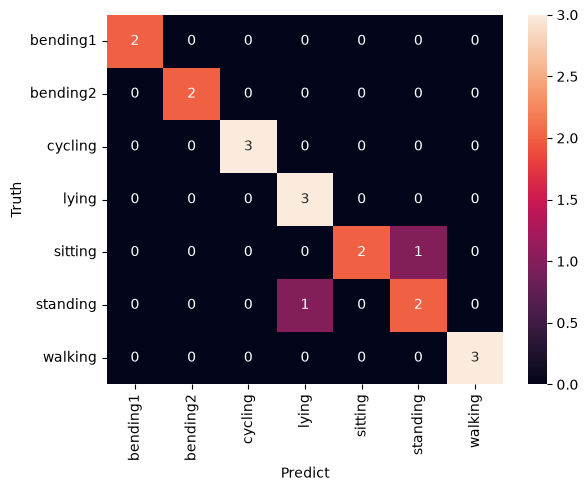

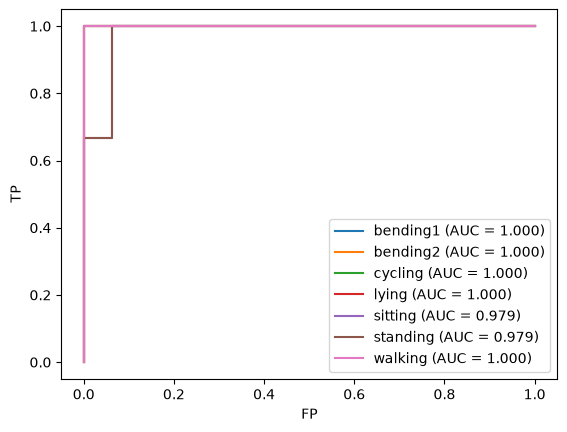

In [13]:
best_multi_l = 1
best_multi_C = 2.782559
x_train_multi, y_train_multi = make_features(train_data, best_multi_l, False)
x_test_multi, y_test_multi = make_features(test_data, best_multi_l, False)
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_multi)
x_test_scaled = scaler.transform(x_test_multi)
multi_model = LogisticRegression(l1_ratio=1, solver="saga", C=best_multi_C, max_iter=20000)
multi_model.fit(x_train_scaled, y_train_multi)
y_pred_multi = multi_model.predict(x_test_scaled)
y_prob_multi = multi_model.predict_proba(x_test_scaled)
test_error = 1 - multi_model.score(x_test_scaled, y_test_multi)
print("Test error:", test_error)

cm_multi = confusion_matrix(y_test_multi, y_pred_multi, labels=acts)
sns.heatmap(
    cm_multi,
    annot=True,
    fmt="d",
    xticklabels=acts,
    yticklabels=acts
)
plt.xlabel("Predict")
plt.ylabel("Truth")
plt.show()

y_test_bin = label_binarize(y_test_multi, classes=acts)
for i in range(len(acts)):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob_multi[:, i])
    auc = roc_auc_score(y_test_bin[:, i], y_prob_multi[:, i])
    plt.plot(fpr, tpr, label=f"{acts[i]} (AUC = {auc:.3f})")
plt.xlabel("FP")
plt.ylabel("TP")
plt.legend()
plt.show()

The best cross-validation accuracy is approximately 0.899, with $l=1$ and $C\approx2.783$. The test error is approximately 0.105.

For multiclass classification, the confusion matrix contains the actual classes as rows and the predicted classes as columns. Each diagonal entry represents correctly classified observations, and other entries represent misclassifications. For the multiclass ROC curves, a one-vs-rest approach is used. Each activity is treated as the positive class in turn, while all remaining activities are treated as the negative class.

#### ii. Naive Bayes

In [14]:
nb_res = []

for l in range(1, 21):
    x, y = make_features(train_data, l, False)
    gaussian_scores = []
    multinomial_scores = []
    for train_idx, val_idx in cv.split(x, y):
        x_train = x.iloc[train_idx]
        x_val = x.iloc[val_idx]
        y_train = y[train_idx]
        y_val = y[val_idx]
        gaussian = GaussianNB()
        multinomial = MultinomialNB()
        gaussian.fit(x_train, y_train)
        multinomial.fit(x_train, y_train)
        gaussian_scores.append(gaussian.score(x_val, y_val))
        multinomial_scores.append(multinomial.score(x_val, y_val))
    nb_res.append({
        "l": l,
        "Gaussian CV Accuracy": np.mean(gaussian_scores),
        "Multinomial CV Accuracy": np.mean(multinomial_scores)
    })
nb_res = pd.DataFrame(nb_res)
nb_res

best_gaussian_score = nb_res["Gaussian CV Accuracy"].max()
best_multinomial_score = nb_res["Multinomial CV Accuracy"].max()
best_gaussian = nb_res[np.isclose(nb_res["Gaussian CV Accuracy"], best_gaussian_score)][["l", "Gaussian CV Accuracy"]]
best_multinomial = nb_res[np.isclose(nb_res["Multinomial CV Accuracy"], best_multinomial_score)][["l", "Multinomial CV Accuracy"]]
print("Best Gaussian:")
display(best_gaussian)
print("Best Multinomial:")
display(best_multinomial)

d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
d:\USC\Fall 2026\Machine Learning for Da

Best Gaussian:


d:\USC\Fall 2026\Machine Learning for Data Science\Homeworks\HW4\.venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


,l,Gaussian CV Accuracy
0,1,0.869231


Best Multinomial:


,l,Multinomial CV Accuracy
4,5,0.798901


Gaussian NB
Test error: 0.10526315789473684


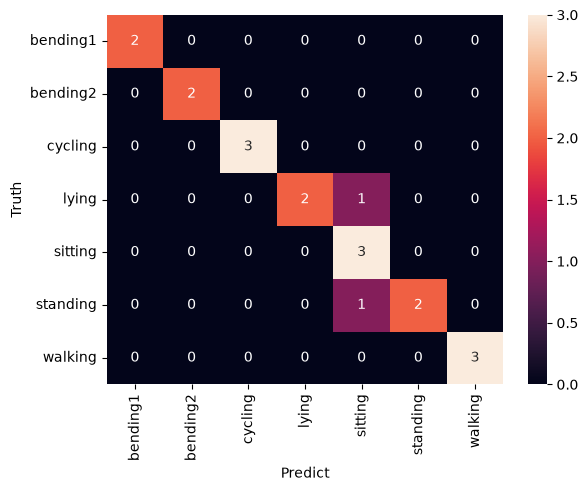

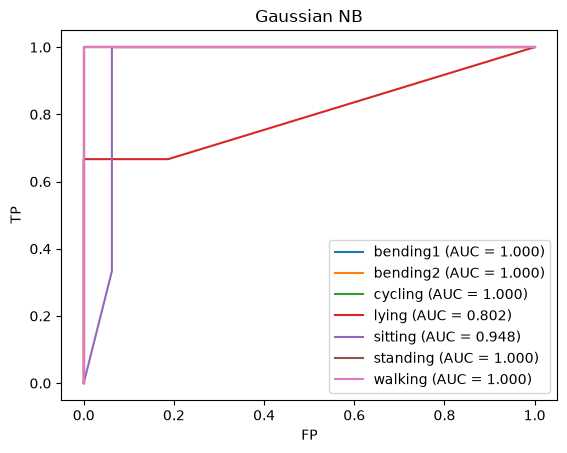

Multinomial NB
Test error: 0.26315789473684215


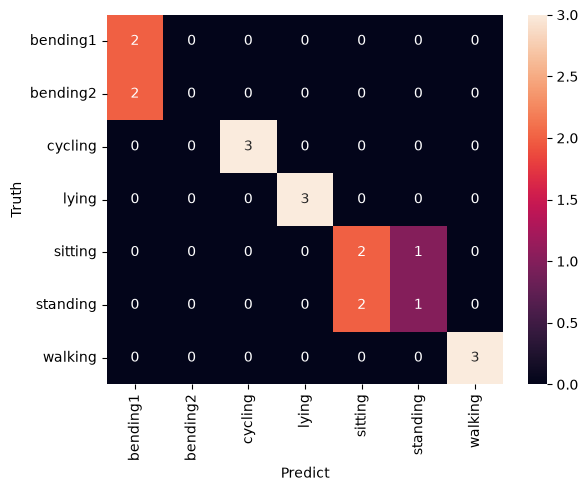

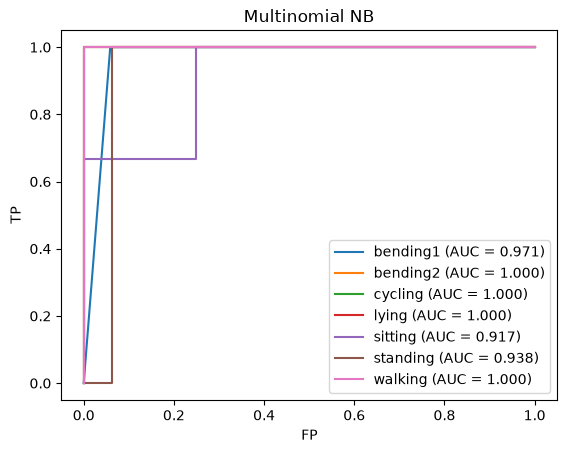

In [15]:
nb_models = [
    ("Gaussian NB", GaussianNB(), 1),
    ("Multinomial NB", MultinomialNB(), 5)
]

for name, model, l in nb_models:
    X_train, y_train = make_features(train_data, l, False)
    X_test, y_test = make_features(test_data, l, False)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)
    error = 1 - model.score(X_test, y_test)
    print(name)
    print("Test error:", error)

    sns.heatmap(
        confusion_matrix(y_test, y_pred, labels=acts),
        annot=True,
        fmt="d",
        xticklabels=acts,
        yticklabels=acts
    )
    plt.xlabel("Predict")
    plt.ylabel("Truth")
    plt.show()

    y_test_bin = label_binarize(y_test, classes=acts)
    for i in range(len(acts)):
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        auc = roc_auc_score(y_test_bin[:, i], y_prob[:, i])
        plt.plot(fpr, tpr, label=f"{acts[i]} (AUC = {auc:.3f})")
    plt.title(name)
    plt.xlabel("FP")
    plt.ylabel("TP")
    plt.legend()
    plt.show()

Gaussian Naive Bayes has a test error of approximately 0.105, while Multinomial Naive Bayes has a test error of approximately 0.263. Therefore Gaussian Naive Bayes performs better than Multinomial Naive Bayes in terms of test classification accuracy for this dataset.

#### ii. Comparison

The L1-penalized multinomial logistic regression and Gaussian Naive Bayes have the same test accuracy, while Multinomial Naive Bayes performs worse. Overall, the L1-penalized multinomial logistic regression performs best because it has the highest cross-validation accuracy, strong ROC/AUC performance, and the lowest test error.

## 3. ISLR 4.8.3

For class $k, X \sim N(\mu_k,\sigma_k^2),$ so its density is

$$
f_k(x)=\frac{1}{\sqrt{2\pi\sigma_k^2}}\exp\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).
$$

Using Bayes' theorem, since $Pr(X=x)$ is the same, the Bayes classifier assigns an observation to the class with the largest value of $\pi_k f_k(x)$. Take the logs and drop constants that don't depend on k:

$$
\delta_k(x)= -\frac{1}{2}\log(\sigma_k^2)-\frac{(x-\mu_k)^2}{2\sigma_k^2}+\log(\pi_k)
= -\frac{x^2}{2\sigma_k^2}+\frac{\mu_k}{\sigma_k^2}x-\frac{\mu_k^2}{2\sigma_k^2}-\frac{1}{2}\log(\sigma_k^2)+\log(\pi_k).
$$

Therefore, the discriminant function contains an $x^2$ term. Since $\sigma_k^2$ can differ across classes, the coefficient of $x^2$ also differs across classes, so the quadratic terms do not cancel when comparing two classes. Therefore the Bayes classifier is quadratic, not linear.

## 4. ISLR 4.8.7

Given that $P(\text{Yes})=0.8, P(\text{No})=0.2,$ and $X\mid \text{Yes} \sim N(10,36), X\mid \text{No} \sim N(0,36),$ use Bayes' theorem,

$$
Pr(Yes\mid X=4)=\frac{Pr(Yes)f_{\text{Yes}}(4)}{P(Yes)f_{Yes}(4)+Pr(No)f_{No}(4)}.
$$

Since both classes have $\sigma^2 = 36$, $\frac{1}{\sqrt{2\pi\sigma^2}}$ in the two normal densities cancels. Therefore,

$$
Pr(Yes\mid X=4)=\frac{0.8\exp\left(-\frac{(4-10)^2}{2*36}\right)}{0.8\exp\left(-\frac{(4-10)^2}{2*36}\right)+0.2\exp\left(-\frac{(4-0)^2}{2*36}\right)}.
$$

Thus,

$$
Pr(Yes\mid X=4)=\frac{0.8e^{-0.5}}{0.8e^{-0.5}+0.2e^{-2/9}}\approx 0.752.
$$

Therefore, the probability that the company will issue a dividend is approximately **75.2%**.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9